In [211]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [212]:
df = pd.read_csv('matches.csv')

In [213]:
df.sample(2)

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
965,1359490,2023,Delhi,2023-04-11,League,RG Sharma,"Arun Jaitley Stadium, Delhi",Delhi Capitals,Mumbai Indians,Mumbai Indians,field,Mumbai Indians,wickets,6.0,173.0,20.0,N,NaN,MA Gough,R Pandit
143,419134,2009/10,Delhi,2010-03-31,League,KD Karthik,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Delhi Daredevils,bat,Delhi Daredevils,runs,67.0,189.0,20.0,N,NaN,HDPK Dharmasena,SJA Taufel


In [214]:
df['toss_decision'].value_counts()

toss_decision
field    704
bat      391
Name: count, dtype: int64

In [215]:
df1 = df.loc[df['toss_winner'] == df['winner']]['toss_decision'].value_counts()

In [216]:
df1

toss_decision
field    377
bat      177
Name: count, dtype: int64

<Axes: xlabel='toss_decision', ylabel='count'>

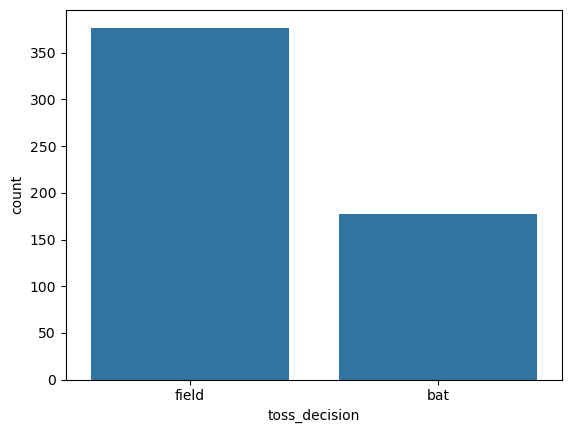

In [217]:
sns.barplot(df1)

In [218]:
df['winner'].unique()

<ArrowStringArray>
[      'Kolkata Knight Riders',         'Chennai Super Kings',
            'Delhi Daredevils', 'Royal Challengers Bangalore',
            'Rajasthan Royals',             'Kings XI Punjab',
             'Deccan Chargers',              'Mumbai Indians',
               'Pune Warriors',        'Kochi Tuskers Kerala',
                           nan,         'Sunrisers Hyderabad',
     'Rising Pune Supergiants',               'Gujarat Lions',
      'Rising Pune Supergiant',              'Delhi Capitals',
                'Punjab Kings',              'Gujarat Titans',
        'Lucknow Super Giants', 'Royal Challengers Bengaluru']
Length: 20, dtype: str

In [219]:
cols = ['winner','team1','team2','toss_winner']
df[cols] = df[cols].replace({'Royal Challengers Bangalore' : 'Royal Challengers Bengaluru'})

In [220]:
df['winner'].unique()

<ArrowStringArray>
[      'Kolkata Knight Riders',         'Chennai Super Kings',
            'Delhi Daredevils', 'Royal Challengers Bengaluru',
            'Rajasthan Royals',             'Kings XI Punjab',
             'Deccan Chargers',              'Mumbai Indians',
               'Pune Warriors',        'Kochi Tuskers Kerala',
                           nan,         'Sunrisers Hyderabad',
     'Rising Pune Supergiants',               'Gujarat Lions',
      'Rising Pune Supergiant',              'Delhi Capitals',
                'Punjab Kings',              'Gujarat Titans',
        'Lucknow Super Giants']
Length: 19, dtype: str

In [221]:
df.head(2)

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bengaluru,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri


In [222]:
winner_grp = df.groupby('winner')

In [223]:
rcb_wins = winner_grp.get_group('Royal Challengers Bengaluru')['winner'].value_counts()
csk_wins = winner_grp.get_group('Chennai Super Kings')['winner'].value_counts()

In [224]:
win_compare = pd.concat({
    'RCB wins' : rcb_wins,
    'CSK wins' : csk_wins
}, names=['group', 'winner']).reset_index(name='count')

<Axes: xlabel='winner', ylabel='count'>

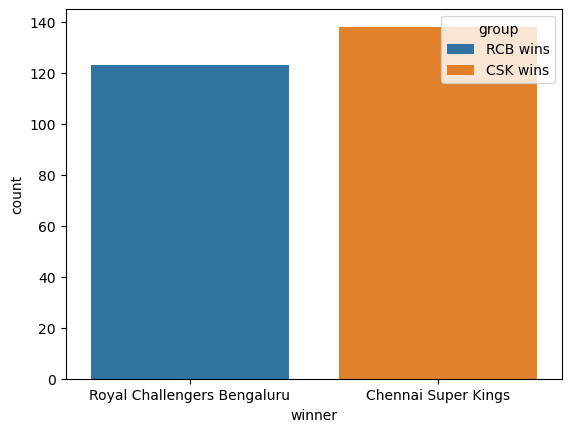

In [225]:
sns.barplot(win_compare,  x='winner', y='count', hue='group')

In [226]:
rcb_match_winner_toss_decision = winner_grp.get_group('Royal Challengers Bengaluru')['toss_decision'].value_counts()
csk_match_winner_toss_decision = winner_grp.get_group('Chennai Super Kings')['toss_decision'].value_counts()

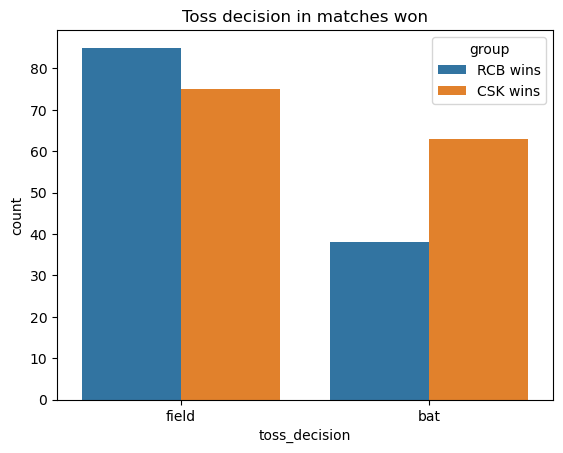

In [227]:
win_compare_as_toss_winner = pd.concat({
    # 'All teams (toss & match winner)': df1,
    'RCB wins': rcb_match_winner_toss_decision,
    'CSK wins' : csk_match_winner_toss_decision
}, names=['group', 'toss_decision']).reset_index(name='count')

sns.barplot(data=win_compare_as_toss_winner, x='toss_decision', y='count', hue='group')
plt.title('Toss decision in matches won')
plt.show()


In [228]:
df.sample(5)

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
491,829775,2015,Chandigarh,2015-05-03,League,LMP Simmons,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Mumbai Indians,Mumbai Indians,bat,Mumbai Indians,runs,23.0,173.0,20.0,N,NaN,RK Illingworth,VA Kulkarni
135,419128,2009/10,Bangalore,2010-03-25,League,KM Jadhav,M Chinnaswamy Stadium,Royal Challengers Bengaluru,Delhi Daredevils,Royal Challengers Bengaluru,field,Delhi Daredevils,runs,17.0,184.0,20.0,N,NaN,BG Jerling,RE Koertzen
212,501236,2011,Chennai,2011-05-01,League,JA Morkel,"MA Chidambaram Stadium, Chepauk",Chennai Super Kings,Deccan Chargers,Chennai Super Kings,bat,Chennai Super Kings,runs,19.0,166.0,20.0,N,NaN,Aleem Dar,RB Tiffin
1002,1359527,2023,Kolkata,2023-05-08,League,AD Russell,"Eden Gardens, Kolkata",Punjab Kings,Kolkata Knight Riders,Punjab Kings,bat,Kolkata Knight Riders,wickets,5.0,180.0,20.0,N,NaN,A Totre,J Madanagopal
463,829715,2015,Delhi,2015-04-12,League,DJ Hooda,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,field,Rajasthan Royals,wickets,3.0,185.0,20.0,N,NaN,SD Fry,CB Gaffaney


In [229]:
df['season'].unique()

<ArrowStringArray>
['2007/08',    '2009', '2009/10',    '2011',    '2012',    '2013',    '2014',
    '2015',    '2016',    '2017',    '2018',    '2019', '2020/21',    '2021',
    '2022',    '2023',    '2024']
Length: 17, dtype: str

In [230]:
df['season'] = df['season'].replace({
    '2007/08' : '2007',
    '2009/10' : '2010',
    '2020/21' : '2020'
})

In [231]:
df['season'].unique()

<ArrowStringArray>
['2007', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016',
 '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']
Length: 17, dtype: str

In [243]:
df['season'] = df['season'].astype('int')

In [244]:
df['season'].dtype

dtype('int64')

In [256]:
grp_data_winner_season = df.groupby('winner')
csk_win_eachyear = grp_data_winner_season.get_group('Chennai Super Kings')['season'].value_counts()
rcb_win_eachyear = grp_data_winner_season.get_group('Royal Challengers Bengaluru')['season'].value_counts()


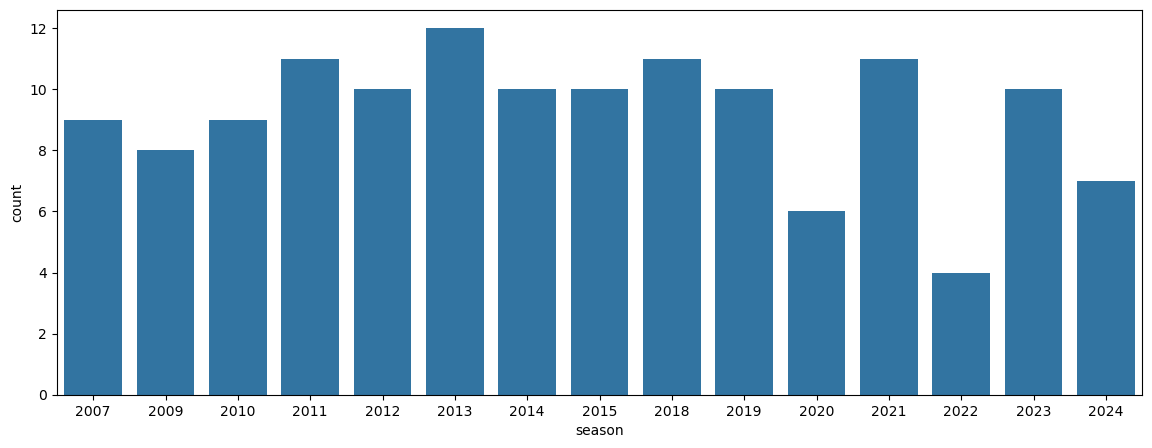

In [259]:
plt.figure(figsize=(14, 5))
sns.barplot(csk_win_eachyear)
plt.show()

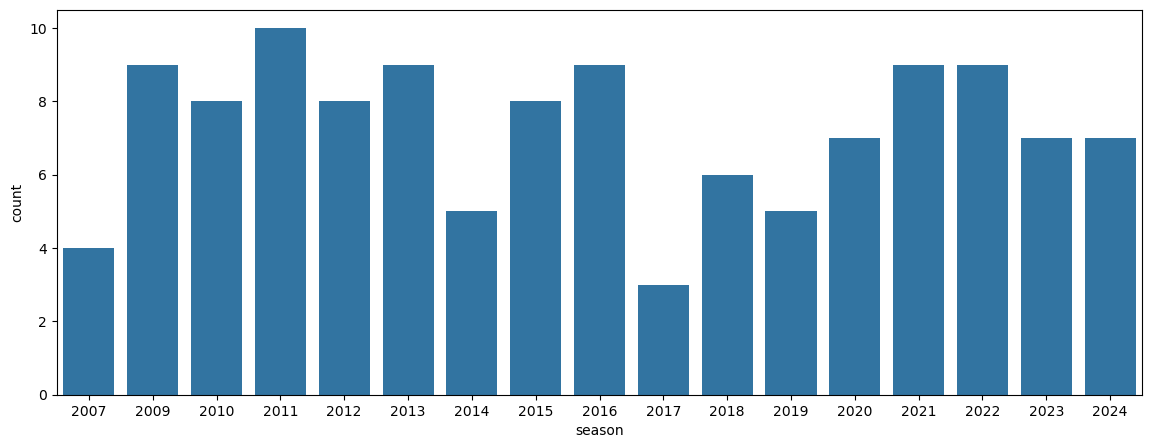

In [260]:
plt.figure(figsize=(14, 5))
sns.barplot(rcb_win_eachyear)
plt.show()

In [268]:
compare_rcb_csk_win_eachyear = pd.concat({
    'CSK' : csk_win_eachyear,
    'RCB' : rcb_win_eachyear
}, names=['team', 'season']).reset_index(name='wins')

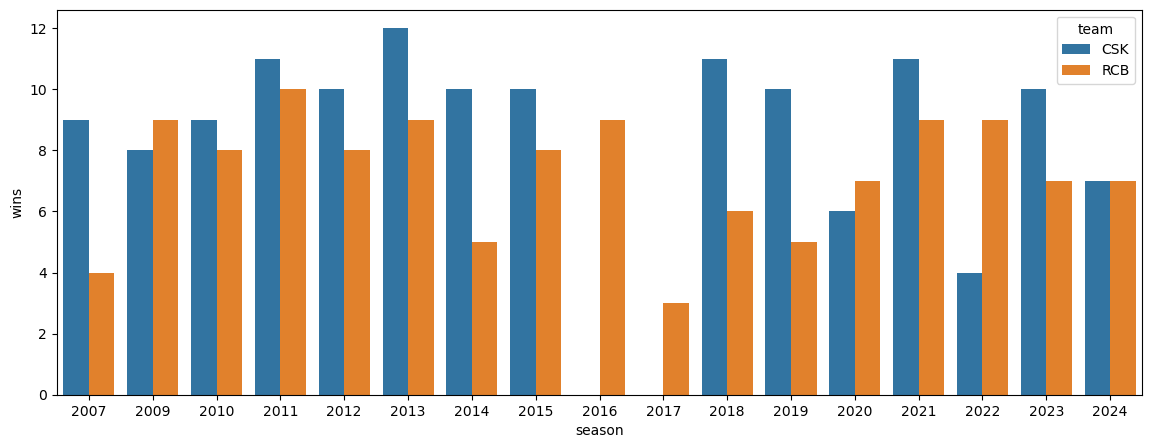

In [271]:
plt.figure(figsize=(14, 5))
sns.barplot(data=compare_rcb_csk_win_eachyear, x='season', y='wins', hue='team')
plt.show()

In [275]:
grp_season = df.groupby('season')

In [286]:
mean_each_season = grp_season['target_runs'].mean()
median_each_season = grp_season['target_runs'].median()


In [295]:
mean_meadian_run_eachyear = pd.concat({
    'mean' : mean_each_season,
    'median' : median_each_season
}, names=['Aggregator fn', 'season']).reset_index(name='values')

In [309]:
mean_meadian_run_eachyear

,Aggregator fn,season,values
0,mean,2007,159.775862
1,mean,2009,148.807018
2,mean,2010,165.783333
3,mean,2011,154.041667
4,mean,2012,158.540541
5,mean,2013,156.894737
6,mean,2014,162.383333
7,mean,2015,164.706897
8,mean,2016,160.783333
9,mean,2017,165.406780


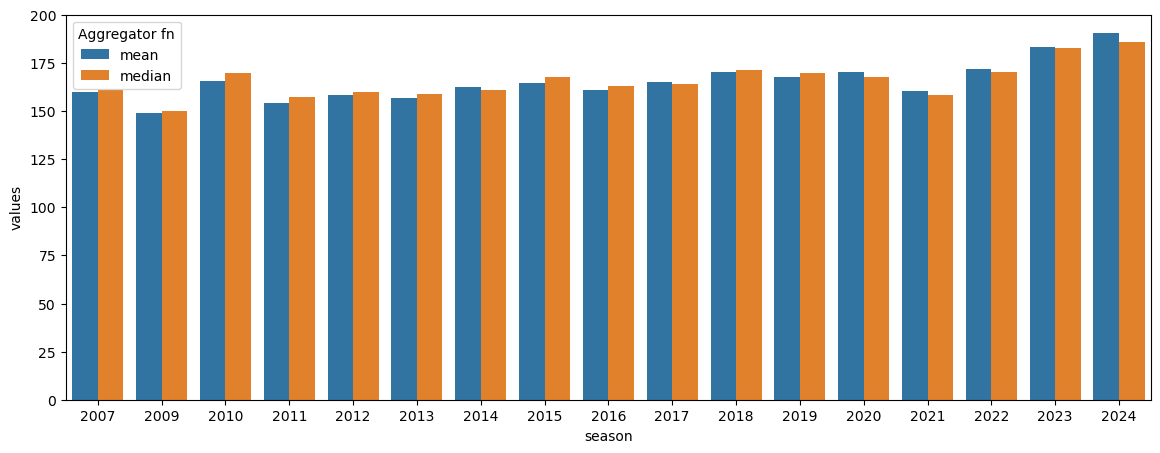

In [ ]:
plt.figure(figsize=(14, 5))
sns.barplot(mean_meadian_run_eachyear, x='season', y='values', hue='Aggregator fn')
plt.show()

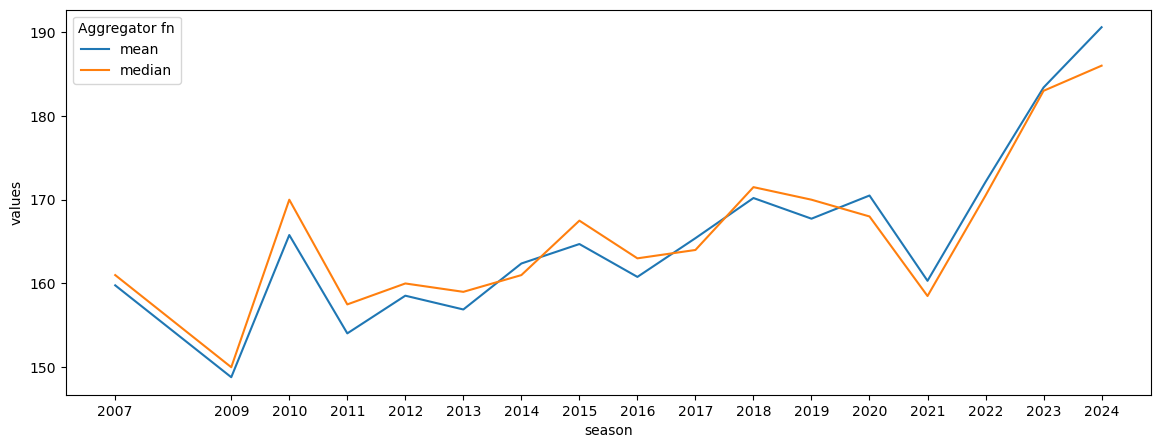

In [310]:
plt.figure(figsize=(14, 5))
sns.lineplot(mean_meadian_run_eachyear, x='season', y='values', hue='Aggregator fn', markers='o')
plt.xticks(mean_meadian_run_eachyear['season'].unique())
plt.show()

In [311]:
df.sample(5)

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
455,734045,2014,Mumbai,2014-05-28,Eliminator,SK Raina,Brabourne Stadium,Chennai Super Kings,Mumbai Indians,Chennai Super Kings,field,Chennai Super Kings,wickets,7.0,174.0,20.0,N,NaN,VA Kulkarni,BNJ Oxenford
641,1136566,2018,Jaipur,2018-04-11,League,SV Samson,Sawai Mansingh Stadium,Rajasthan Royals,Delhi Daredevils,Delhi Daredevils,field,Rajasthan Royals,runs,10.0,71.0,6.0,N,D/L,KN Ananthapadmanabhan,Nitin Menon
320,548380,2012,Chennai,2012-05-25,Qualifier 2,M Vijay,"MA Chidambaram Stadium, Chepauk",Delhi Daredevils,Chennai Super Kings,Delhi Daredevils,field,Chennai Super Kings,runs,86.0,223.0,20.0,N,NaN,BR Doctrove,SJA Taufel
76,392201,2009,Centurion,2009-04-30,League,DP Nannes,SuperSport Park,Deccan Chargers,Delhi Daredevils,Delhi Daredevils,field,Delhi Daredevils,wickets,6.0,149.0,20.0,N,NaN,GAV Baxter,AM Saheba
556,980979,2016,Visakhapatnam,2016-05-10,League,A Zampa,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,Rising Pune Supergiants,Sunrisers Hyderabad,Sunrisers Hyderabad,bat,Sunrisers Hyderabad,runs,4.0,138.0,20.0,N,NaN,CB Gaffaney,VK Sharma


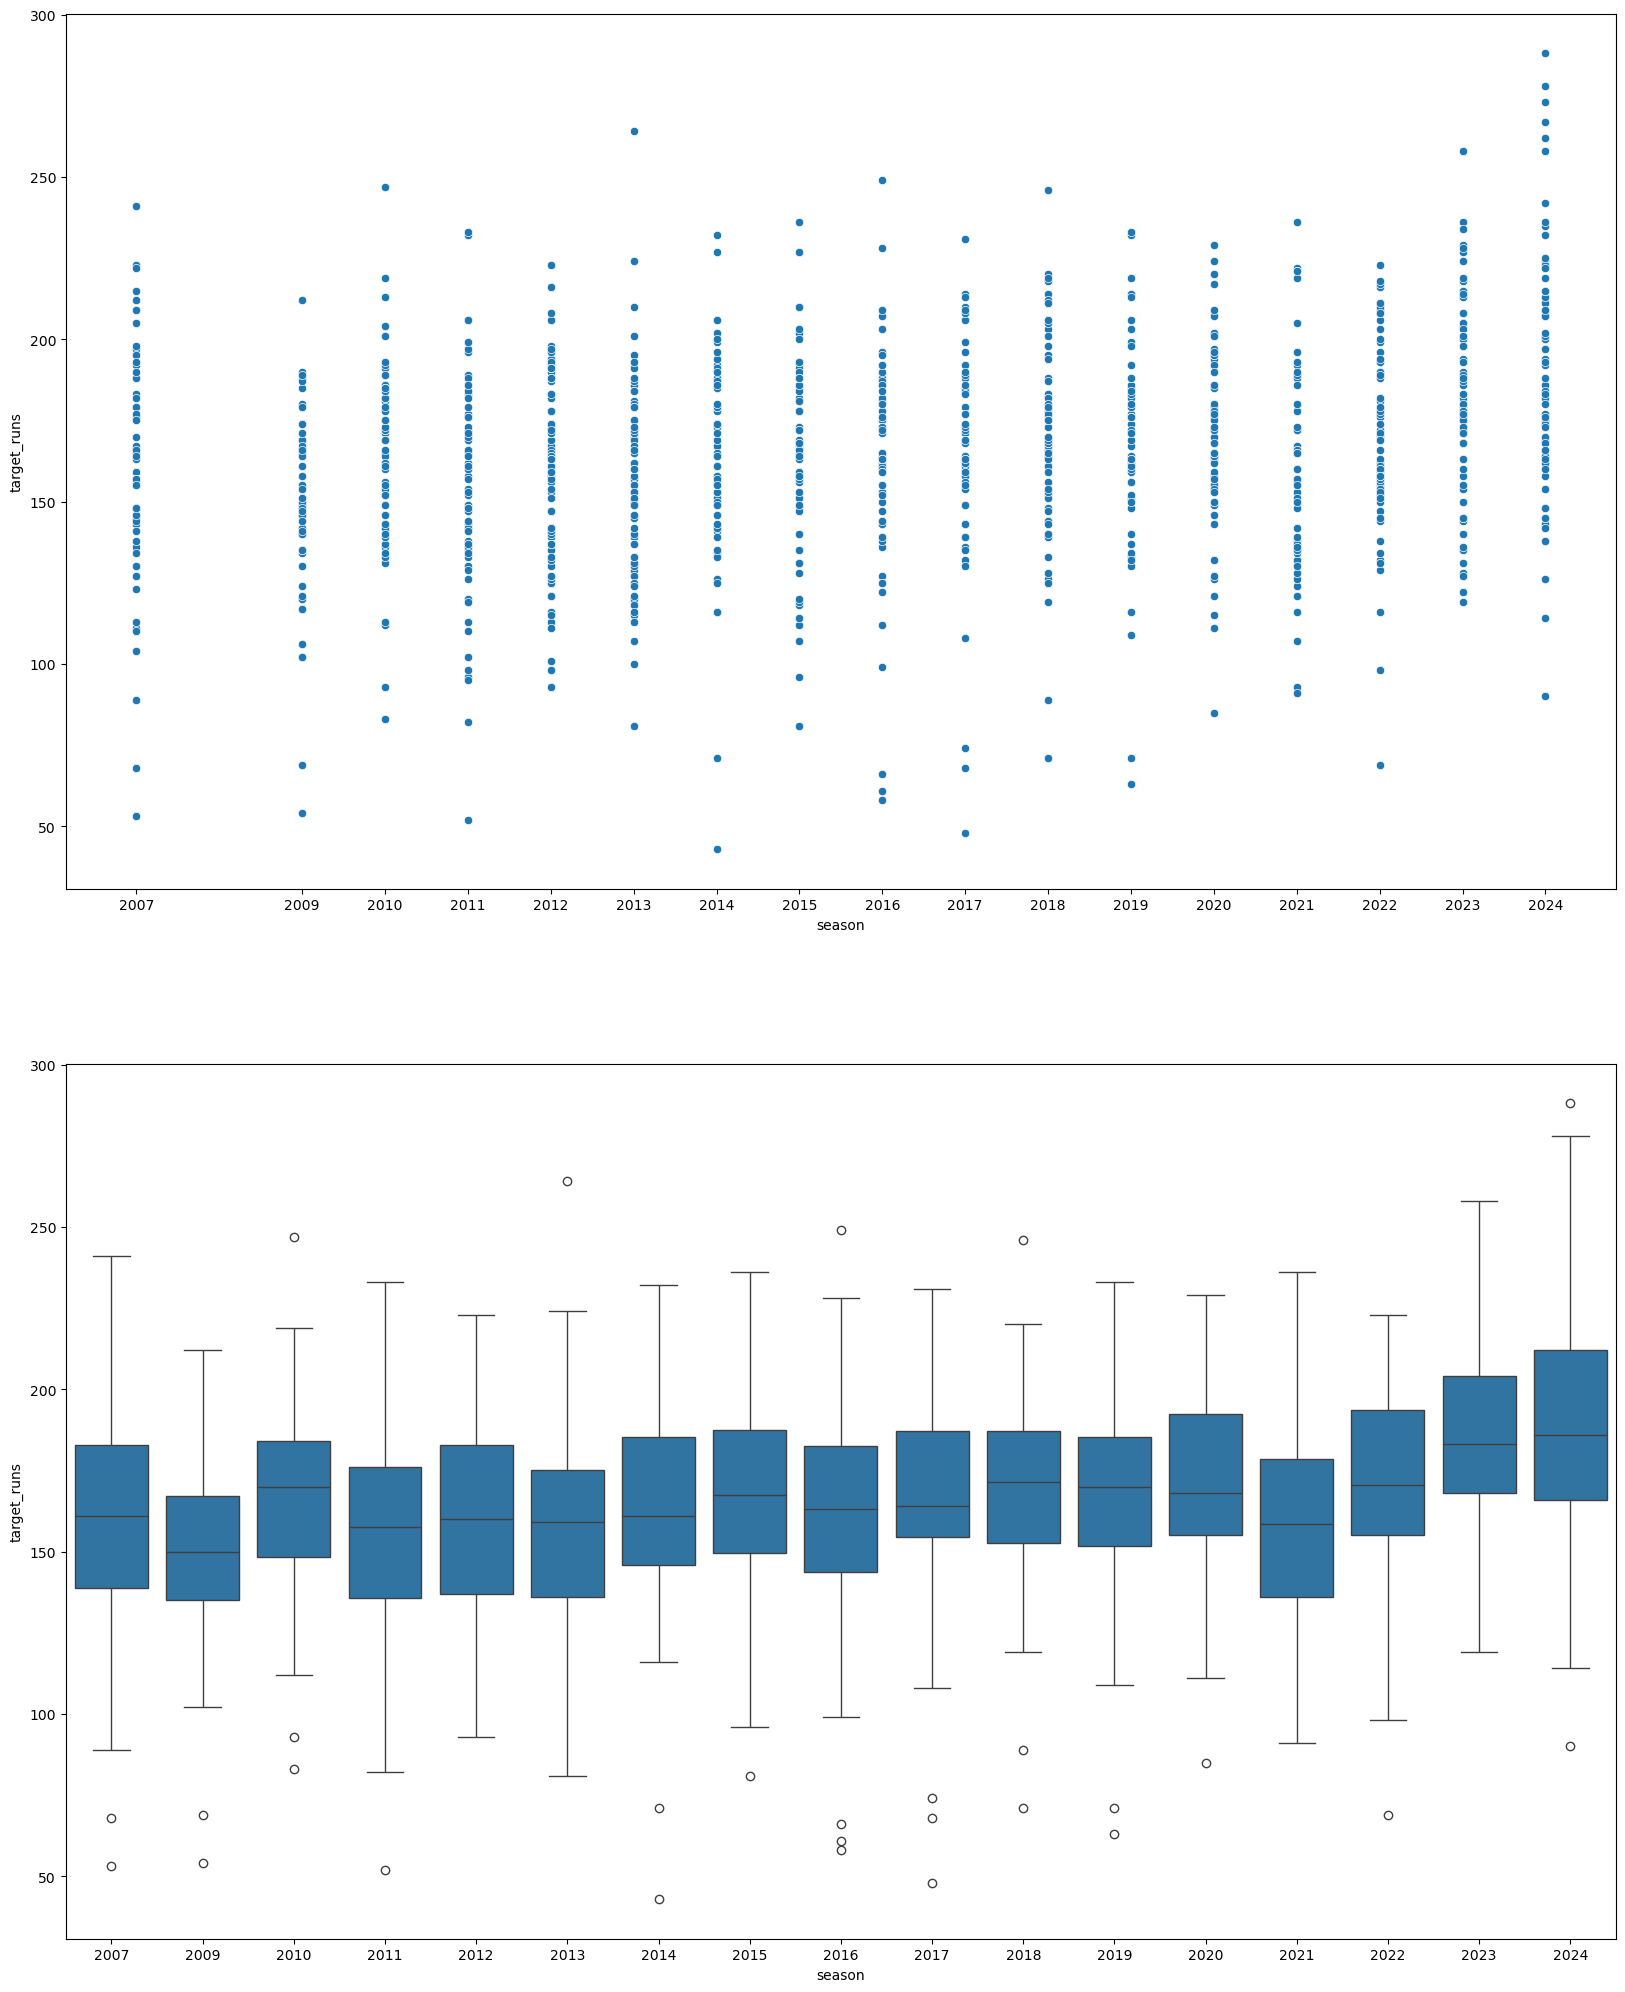

In [331]:
fig,axes = plt.subplots(2, 1, figsize=(20, 25))
sns.scatterplot(df, y=df['target_runs'], x=df['season'], ax=axes[0])
sns.boxplot(df, y=df['target_runs'], x=df['season'], ax=axes[1])
axes[0].set_xticks(df['season'].unique())
plt.show()